In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn

from mlkit.blocks.attention import SelfAttention, SelfAttentionConfig, scaled_dot_product_attention
from mlkit.blocks.embeddings import SinusoidalPositionalEmbedding
from mlkit.blocks.transformer import TransformerEncoderBlock, TransformerEncoderBlockConfig
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.visual.attention import plot_attention
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

setup_logging()
use_style()

SEED = 42
MAX_LEN = 64
D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
DROPOUT = 0.1

BATCH = 2
SEQ_LEN = 8
PADDED = 3

RUN_NAME = f"lab3.1_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

Positional table: (64, 64) | range [-1.0, 1.0]


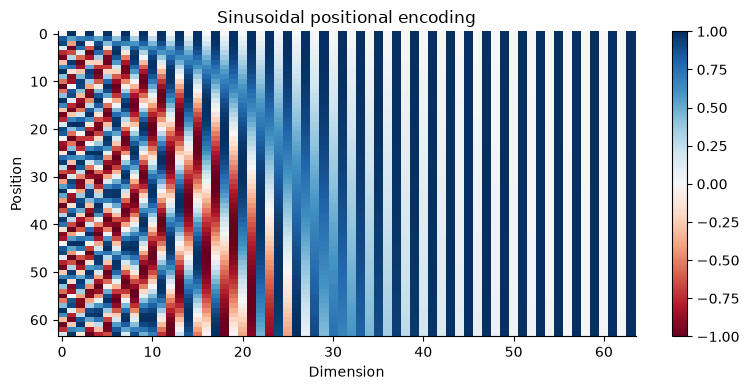

In [2]:
table = SinusoidalPositionalEmbedding(MAX_LEN, D_MODEL).table
print(f"Positional table: {tuple(table.shape)} | range [{table.min().item():.1f}, {table.max().item():.1f}]")

fig, ax = plt.subplots(figsize=(8, 4))
image = ax.imshow(table.numpy(), cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
fig.colorbar(image, ax=ax)
ax.grid(False)
ax.set_xlabel("Dimension")
ax.set_ylabel("Position")
ax.set_title("Sinusoidal positional encoding")
fig.tight_layout()
saver.save(fig, "sinusoidal_positions");

In [3]:
X = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]).unsqueeze(0)
scores = X @ X.transpose(-2, -1) / X.size(-1) ** 0.5
output, weights = scaled_dot_product_attention(X, X, X)

print("X:", tuple(X.shape))
print("Scores QK^T / sqrt(d_k):")
print(scores[0].numpy().round(3))
print("Attention weights:")
print(weights[0].numpy().round(3))
print("Output:")
print(output[0].numpy().round(3))
print("Row sums:", weights.sum(dim=-1)[0].numpy().round(6))
torch.testing.assert_close(weights.sum(dim=-1), torch.ones(1, 3))

X: (1, 3, 2)
Scores QK^T / sqrt(d_k):
[[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]
Attention weights:
[[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]]
Output:
[[0.802 0.599]
 [0.599 0.802]
 [0.752 0.752]]
Row sums: [1. 1. 1.]


Weights with x3 masked as key:
[[0.67 0.33 0.  ]
 [0.33 0.67 0.  ]
 [0.5  0.5  0.  ]]


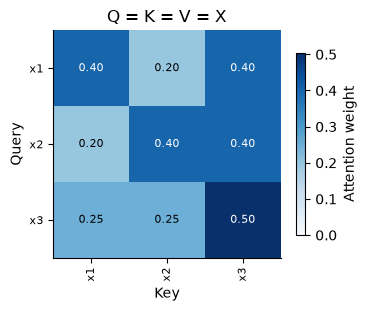

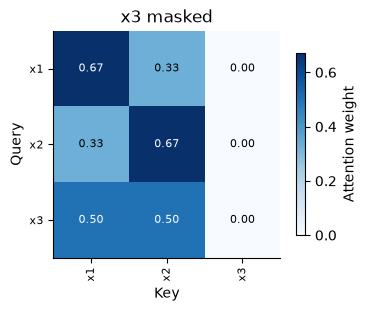

In [4]:
elements = ["x1", "x2", "x3"]
toy_mask = torch.tensor([[True, True, False]])
_, masked_weights = scaled_dot_product_attention(X, X, X, toy_mask[:, None, :])

print("Weights with x3 masked as key:")
print(masked_weights[0].numpy().round(3))

saver.save(plot_attention(weights[0], elements, ["Q = K = V = X"], annotate=True), "toy_attention")
saver.save(plot_attention(masked_weights[0], elements, ["x3 masked"], annotate=True), "toy_attention_masked");

In [5]:
seed_everything(SEED)
x = torch.randn(BATCH, SEQ_LEN, D_MODEL)
mask = torch.ones(BATCH, SEQ_LEN, dtype=torch.bool)
mask[1, -PADDED:] = False

attention = SelfAttention(D_MODEL, SelfAttentionConfig(num_heads=NUM_HEADS)).eval()
with torch.no_grad():
    out, attn = attention(x, mask)

print(f"Input: {tuple(x.shape)} | output: {tuple(out.shape)} | weights: {tuple(attn.shape)}")
print(f"Heads: {NUM_HEADS} | head dim: {attention.head_dim} | parameters: {sum(p.numel() for p in attention.parameters()):,}")
print(f"Max weight on padded keys: {attn[1, :, :, -PADDED:].max().item():.1e}")
torch.testing.assert_close(attn.sum(dim=-1), torch.ones(BATCH, NUM_HEADS, SEQ_LEN))

Input: (2, 8, 64) | output: (2, 8, 64) | weights: (2, 4, 8, 8)
Heads: 4 | head dim: 16 | parameters: 16,640
Max weight on padded keys: 0.0e+00


In [6]:
reference = nn.MultiheadAttention(D_MODEL, NUM_HEADS, batch_first=True).eval()
with torch.no_grad():
    reference.in_proj_weight.copy_(attention.w_qkv.weight)
    reference.in_proj_bias.copy_(attention.w_qkv.bias)
    reference.out_proj.weight.copy_(attention.w_out.weight)
    reference.out_proj.bias.copy_(attention.w_out.bias)
    ref_out, ref_attn = reference(x, x, x, key_padding_mask=~mask, need_weights=True, average_attn_weights=False)

print(f"nn.MultiheadAttention: output {tuple(ref_out.shape)} | weights {tuple(ref_attn.shape)}")
print(f"Max |output difference|: {(out - ref_out).abs().max().item():.1e}")
print(f"Max |weights difference|: {(attn - ref_attn).abs().max().item():.1e}")
torch.testing.assert_close(out, ref_out)
torch.testing.assert_close(attn, ref_attn)

nn.MultiheadAttention: output (2, 8, 64) | weights (2, 4, 8, 8)
Max |output difference|: 1.2e-07
Max |weights difference|: 3.0e-08


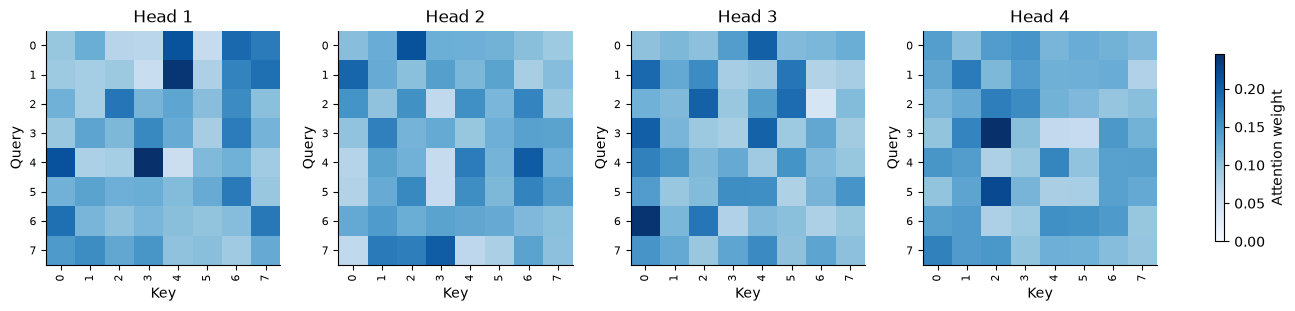

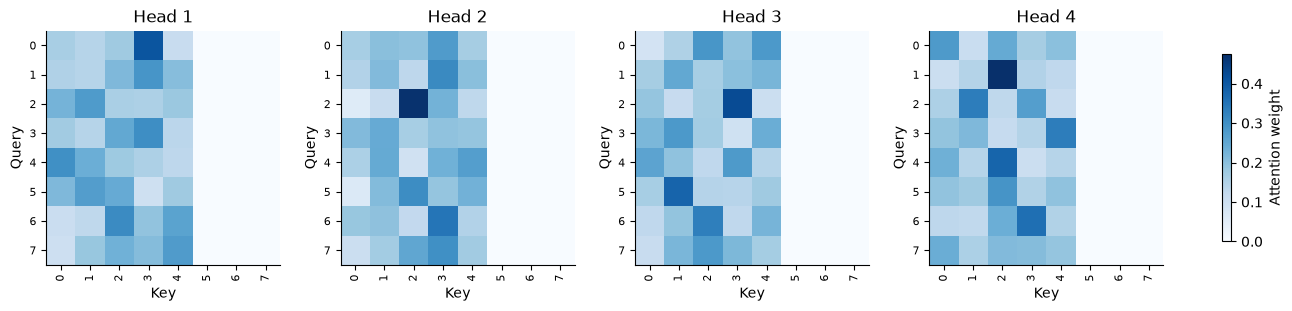

In [7]:
heads = [f"Head {head + 1}" for head in range(NUM_HEADS)]
positions = [str(position) for position in range(SEQ_LEN)]

saver.save(plot_attention(attn[0], positions, heads), "heads_untrained")
saver.save(plot_attention(attn[1], positions, heads), "heads_untrained_padded");

In [8]:
block_config = TransformerEncoderBlockConfig(
    ff_dim=FF_DIM,
    attention=SelfAttentionConfig(num_heads=NUM_HEADS, dropout=DROPOUT),
    dropout=DROPOUT,
)
block = TransformerEncoderBlock(D_MODEL, block_config).eval()
print(block)

with torch.no_grad():
    y, block_attn = block(x, mask)

print(f"Input: {tuple(x.shape)} | output: {tuple(y.shape)} | weights: {tuple(block_attn.shape)}")
print(f"Parameters: {sum(p.numel() for p in block.parameters()):,}")

TransformerEncoderBlock(
  (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (attention): SelfAttention(
    (w_qkv): Linear(in_features=64, out_features=192, bias=True)
    (w_out): Linear(in_features=64, out_features=64, bias=True)
  )
  (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (ff): Sequential(
    (0): LinearBlock(
      (0): Linear(in_features=64, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
    )
    (1): LinearBlock(
      (0): Linear(in_features=128, out_features=64, bias=True)
    )
  )
  (dropout): Dropout(p=0.1, inplace=False)
)
Input: (2, 8, 64) | output: (2, 8, 64) | weights: (2, 4, 8, 8)
Parameters: 33,472
